# 🌦️ Rain in Australia — Prediksi `RainTomorrow` (Klasifikasi)
**Kelompok 3 "Satori"** · Data Science Bootcamp Batch 65 · Digital Skola

Alur final project (**Explorer → Conqueror**):
1. **EDA** — Exploratory Data Analysis
2. **Pre-processing** — feature engineering, missing handling, encoding
3. **Model Training** — Logistic Regression vs Random Forest vs XGBoost
4. **Evaluation** — F1, ROC-AUC, Confusion Matrix (data imbalance!)
5. **Save model** — untuk deployment **Streamlit**

> Dataset: [Weather Dataset Rattle Package](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package) — `weatherAUS.csv` (145.460 baris, 49 lokasi, 2007–2017).

## 0. Setup & Library

In [1]:
# Jalankan sekali. Di Google Colab sebagian besar library sudah tersedia.
!pip install -q xgboost

import warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline
plt.rcParams["figure.dpi"] = 110

## 1. Load Dataset

In [2]:
CSV = "weatherAUS.csv"
if not os.path.exists(CSV):
    print("File lokal tidak ditemukan - mengunduh dari GitHub...")
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/septianshft/rain-australia-satori/main/weatherAUS.csv", CSV)

df = pd.read_csv(CSV)

# Parse tanggal robust: coba format ISO dulu, fallback format campuran (mis. M/D/YYYY).
try:
    df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
except ValueError:
    df["Date"] = pd.to_datetime(df["Date"], format="mixed", errors="coerce")
assert df["Date"].isna().sum() == 0, "Ada tanggal yang gagal diparse!"

print("Shape:", df.shape)
df.head()

Shape: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-16,Albury,9.8,27.7,NaN,NaN,NaN,WNW,50.0,NaN,...,50.0,28.0,1013.4,1010.3,0.0,NaN,17.3,26.2,NaN,No
1,2010-02-10,Albury,21.7,35.6,NaN,NaN,NaN,SSW,46.0,NaN,...,64.0,28.0,1018.8,1014.7,NaN,4.0,25.2,32.9,NaN,No
2,2010-02-12,Albury,22.5,29.1,NaN,NaN,NaN,SW,24.0,NaN,...,81.0,67.0,1008.5,1007.8,NaN,7.0,23.4,26.4,NaN,No
3,2011-09-11,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2011-09-12,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("Rentang tanggal :", df["Date"].min().date(), "->", df["Date"].max().date())
print("Jumlah lokasi   :", df["Location"].nunique())
print("Baris duplikat  :", df.duplicated().sum())
print("Total missing   :", f"{df.isna().sum().sum():,} sel ({df.isna().sum().sum()/df.size*100:.1f}%)")
df.info()

Rentang tanggal : 2007-11-01 -> 2017-06-25
Jumlah lokasi   : 49
Baris duplikat  : 0
Total missing   : 343,248 sel (10.3%)
<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[us]
 1   Location       145460 non-null  str           
 2   MinTemp        143975 non-null  float64       
 3   MaxTemp        144199 non-null  float64       
 4   Rainfall       142199 non-null  float64       
 5   Evaporation    82670 non-null   float64       
 6   Sunshine       75625 non-null   float64       
 7   WindGustDir    135134 non-null  str           
 8   WindGustSpeed  135197 non-null  float64       
 9   WindDir9am     134894 non-null  str           
 10  WindDir3pm     141232 non-null  str           
 11  WindSpeed9am   143693 non-null  float64       
 12  WindSpeed3pm   142398 non-null  float64      

In [4]:
df

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-16,Albury,9.8,27.7,NaN,NaN,NaN,WNW,50.0,NaN,...,50.0,28.0,1013.4,1010.3,0.0,NaN,17.3,26.2,NaN,No
1,2010-02-10,Albury,21.7,35.6,NaN,NaN,NaN,SSW,46.0,NaN,...,64.0,28.0,1018.8,1014.7,NaN,4.0,25.2,32.9,NaN,No
2,2010-02-12,Albury,22.5,29.1,NaN,NaN,NaN,SW,24.0,NaN,...,81.0,67.0,1008.5,1007.8,NaN,7.0,23.4,26.4,NaN,No
3,2011-09-11,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2011-09-12,Albury,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145455,2016-07-31,Uluru,5.6,28.7,0.0,NaN,NaN,WNW,39.0,NaN,...,45.0,12.0,1018.7,1014.1,NaN,NaN,13.6,27.9,No,No
145456,2016-09-08,Uluru,15.1,31.1,0.0,NaN,NaN,WSW,48.0,NaN,...,63.0,24.0,1015.8,1012.8,8.0,NaN,21.0,30.3,No,No
145457,2017-02-09,Uluru,25.6,40.6,0.2,NaN,NaN,ENE,56.0,NaN,...,47.0,27.0,1007.3,1003.2,NaN,1.0,32.0,38.6,No,No
145458,2017-05-19,Uluru,4.3,22.4,0.0,NaN,NaN,ENE,26.0,NaN,...,71.0,33.0,1020.1,1014.8,NaN,NaN,10.9,21.3,No,No


## 2. Exploratory Data Analysis (EDA)
Kita bedah: missing value, keseimbangan target, pola waktu/musim, pengaruh lokasi,
sinyal tiap fitur, dan kualitas data.

### 2.1 Missing Values

,n_missing,pct
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10


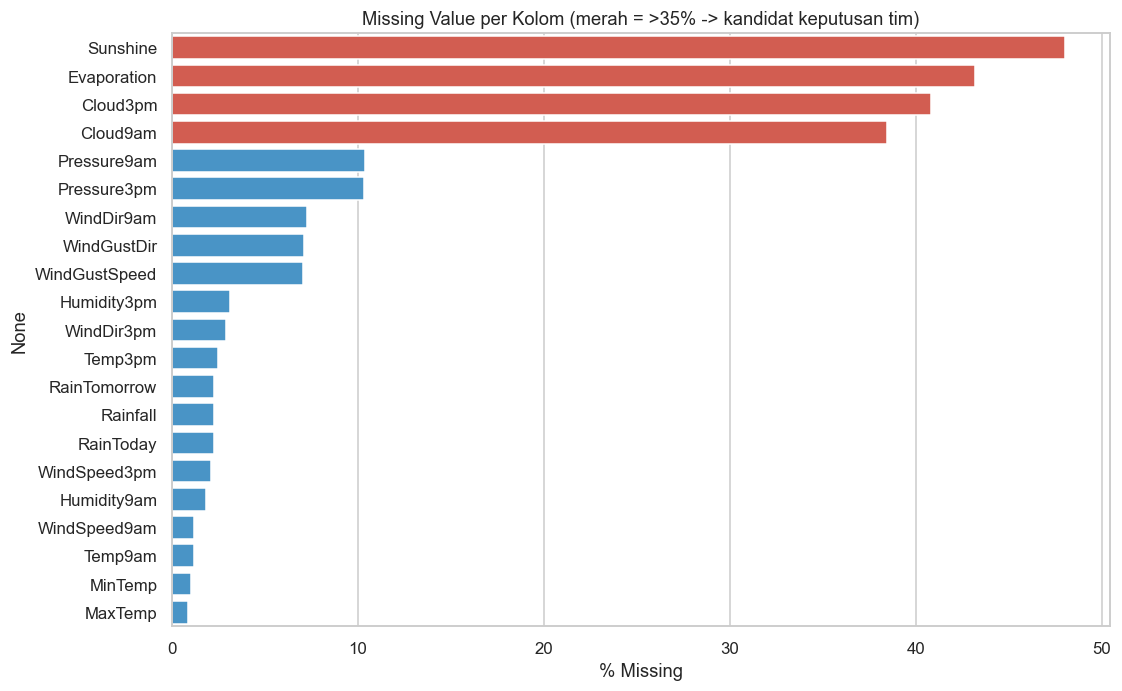

In [5]:
miss = df.isna().sum()
miss_tab = pd.DataFrame({"n_missing": miss, "pct": (miss/len(df)*100).round(2)})
miss_tab = miss_tab[miss_tab.n_missing > 0].sort_values("pct", ascending=False)
display(miss_tab)

plt.figure(figsize=(11, 7))
sns.barplot(x=miss_tab["pct"], y=miss_tab.index,
            hue=miss_tab["pct"] > 35, palette={True: "#e74c3c", False: "#3498db"}, legend=False)
plt.xlabel("% Missing")
plt.title("Missing Value per Kolom (merah = >35% -> kandidat keputusan tim)")
plt.show()

### 2.2 Keseimbangan Target (`RainTomorrow`)

No  : 110,316 (77.6%)
Yes : 31,877 (22.4%)
Imbalance 1 : 3.46  ->  baseline 'selalu jawab No' = 77.6% akurasi


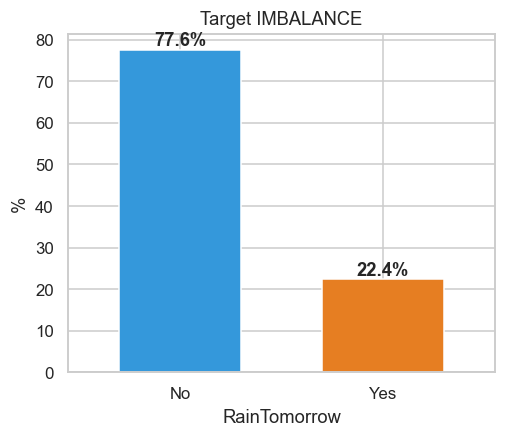

In [6]:
dta = df.dropna(subset=["RainTomorrow"]).copy()
dta["rain_flag"] = (dta["RainTomorrow"] == "Yes").astype(int)

vc = dta["RainTomorrow"].value_counts()
pct = dta["RainTomorrow"].value_counts(normalize=True) * 100
print(f"No  : {vc['No']:,} ({pct['No']:.1f}%)")
print(f"Yes : {vc['Yes']:,} ({pct['Yes']:.1f}%)")
print(f"Imbalance 1 : {vc['No']/vc['Yes']:.2f}  ->  baseline 'selalu jawab No' = {pct['No']:.1f}% akurasi")

plt.figure(figsize=(5, 4))
pct.plot.bar(color=["#3498db", "#e67e22"], width=0.6)
plt.ylabel("%"); plt.title("Target IMBALANCE"); plt.xticks(rotation=0)
for i, v in enumerate(pct.values):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
plt.show()

### 2.3 Pola Waktu & Musiman

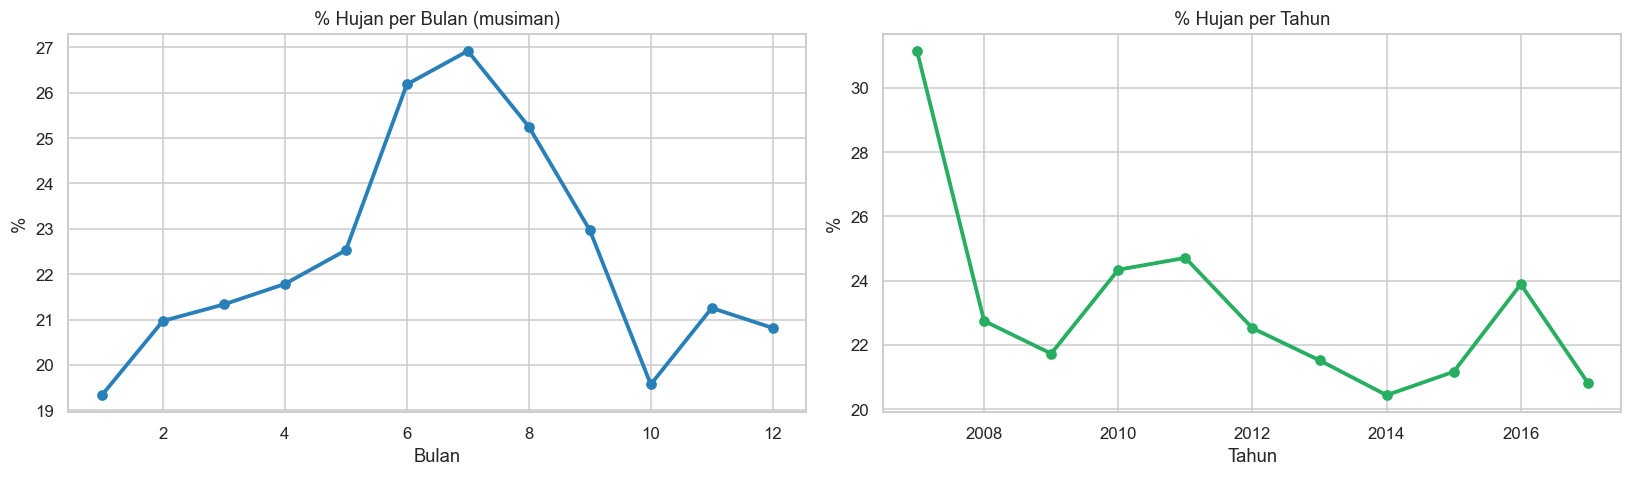

Bulan terbasah: 7 (26.9%)  |  terkering: 1 (19.3%)


In [7]:
dta["Month"] = dta["Date"].dt.month
dta["Year"] = dta["Date"].dt.year
monthly = dta.groupby("Month")["rain_flag"].mean() * 100
yearly = dta.groupby("Year")["rain_flag"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(monthly.index, monthly.values, marker="o", color="#2980b9", lw=2.5)
ax[0].set_title("% Hujan per Bulan (musiman)"); ax[0].set_xlabel("Bulan"); ax[0].set_ylabel("%")
ax[1].plot(yearly.index, yearly.values, marker="o", color="#27ae60", lw=2.5)
ax[1].set_title("% Hujan per Tahun"); ax[1].set_xlabel("Tahun"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()
print("Bulan terbasah:", monthly.idxmax(), f"({monthly.max():.1f}%)  |  terkering:",
      monthly.idxmin(), f"({monthly.min():.1f}%)")

### 2.4 Pengaruh Lokasi

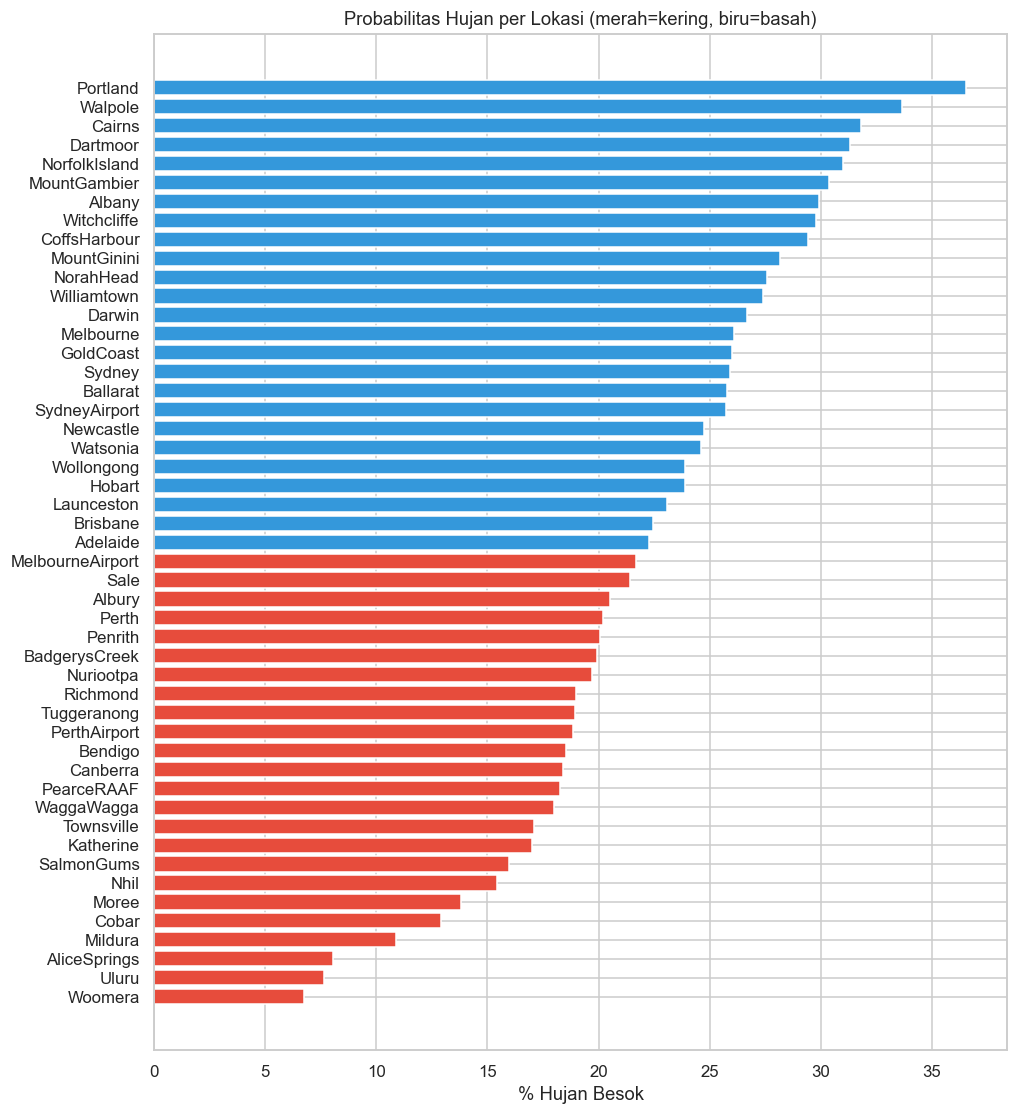

Terkering: {'Woomera': 6.8, 'Uluru': 7.6, 'AliceSprings': 8.1}
Terbasah : {'Cairns': 31.8, 'Walpole': 33.7, 'Portland': 36.5}
Gap antar lokasi: 29.8 poin -> Location = fitur penting


In [8]:
loc = (dta.groupby("Location")["rain_flag"].mean() * 100).sort_values()
plt.figure(figsize=(10, 12))
colors = ["#e74c3c" if v < loc.median() else "#3498db" for v in loc.values]
plt.barh(loc.index, loc.values, color=colors)
plt.xlabel("% Hujan Besok"); plt.title("Probabilitas Hujan per Lokasi (merah=kering, biru=basah)")
plt.show()
print("Terkering:", {k: round(v, 1) for k, v in loc.head(3).items()})
print("Terbasah :", {k: round(v, 1) for k, v in loc.tail(3).items()})
print(f"Gap antar lokasi: {loc.max()-loc.min():.1f} poin -> Location = fitur penting")

### 2.5 Sinyal Fitur Numerik terhadap Target

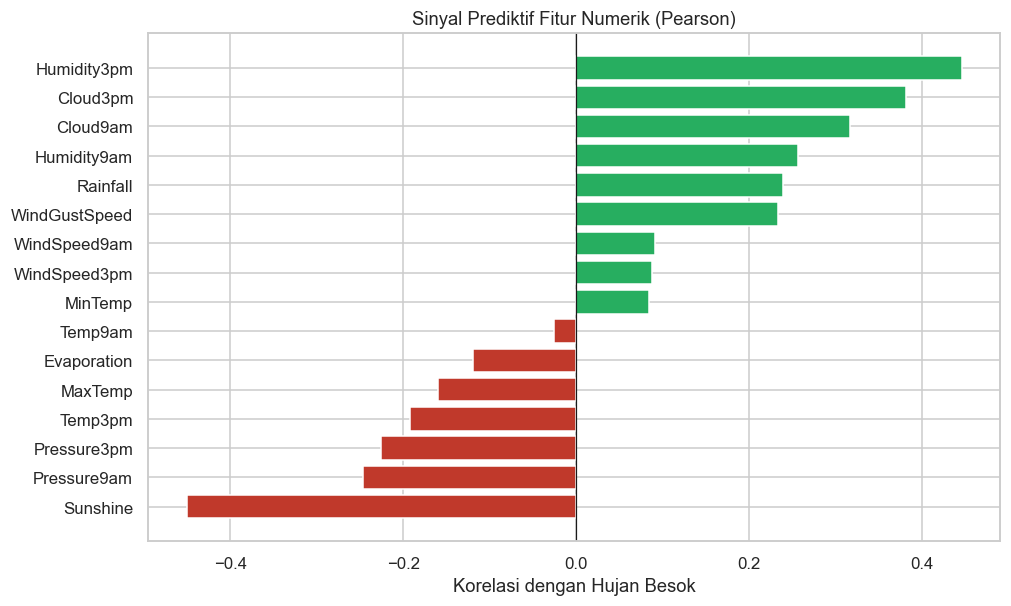

,korelasi
Humidity3pm,0.446
Cloud3pm,0.382
Cloud9am,0.317
Humidity9am,0.257
Rainfall,0.239
WindGustSpeed,0.234
WindSpeed9am,0.091
WindSpeed3pm,0.088
MinTemp,0.084
Temp9am,-0.026


In [9]:
num_cols = ["MinTemp","MaxTemp","Rainfall","Evaporation","Sunshine","WindGustSpeed",
            "WindSpeed9am","WindSpeed3pm","Humidity9am","Humidity3pm","Pressure9am",
            "Pressure3pm","Cloud9am","Cloud3pm","Temp9am","Temp3pm"]
corr = dta[num_cols + ["rain_flag"]].corr()["rain_flag"].drop("rain_flag").sort_values()

plt.figure(figsize=(10, 6))
colors = ["#27ae60" if v > 0 else "#c0392b" for v in corr.values]
plt.barh(corr.index, corr.values, color=colors); plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Korelasi dengan Hujan Besok"); plt.title("Sinyal Prediktif Fitur Numerik (Pearson)")
plt.show()
display(corr.round(3).to_frame("korelasi").sort_values("korelasi", ascending=False))

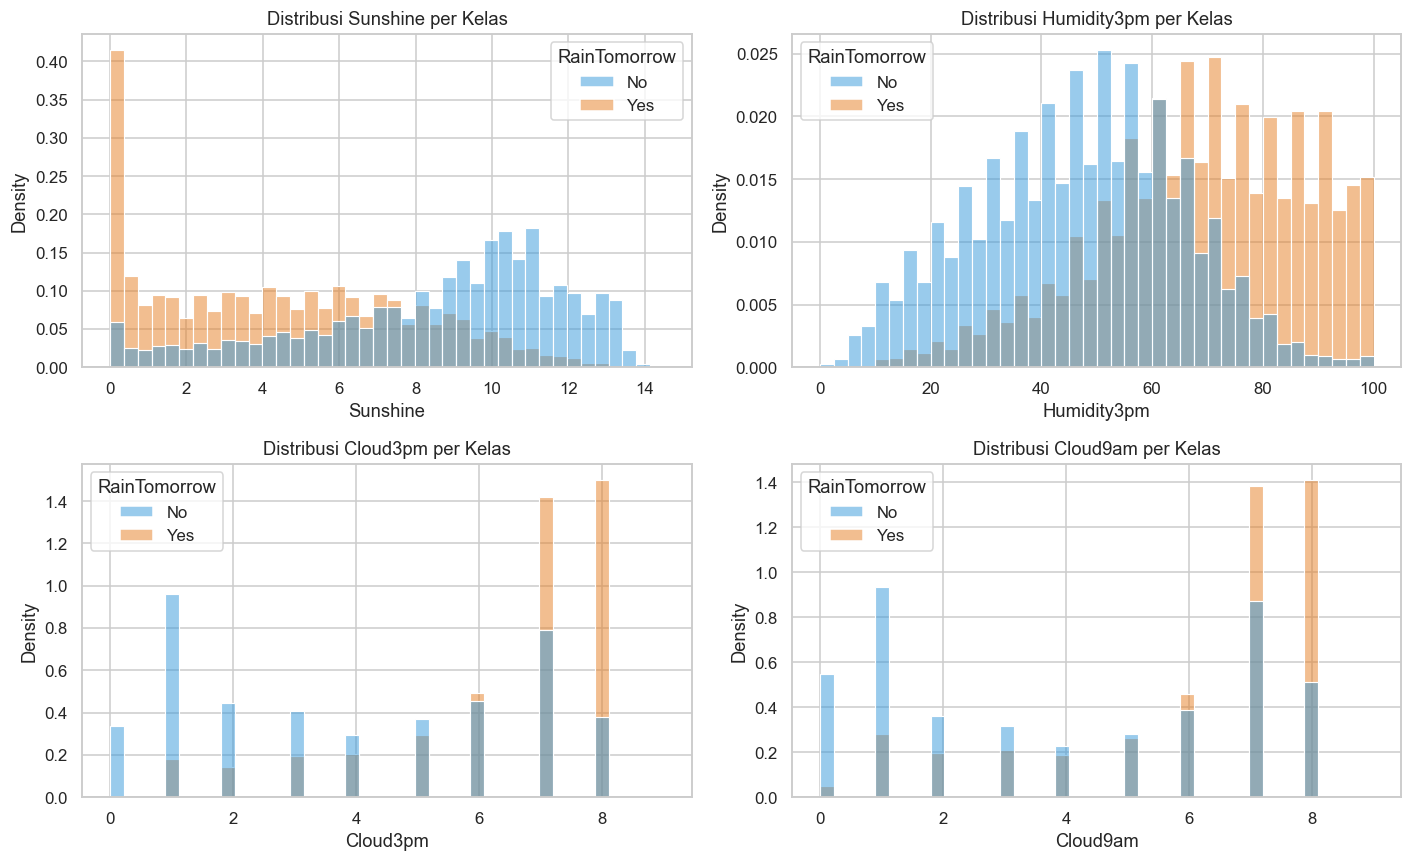

4 prediktor terkuat: ['Sunshine', 'Humidity3pm', 'Cloud3pm', 'Cloud9am']


In [10]:
key = corr.abs().sort_values(ascending=False).head(4).index.tolist()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, f in zip(axes.flat, key):
    sns.histplot(data=dta, x=f, hue="RainTomorrow", bins=40, ax=ax,
                 stat="density", common_norm=False, palette={"No": "#3498db", "Yes": "#e67e22"})
    ax.set_title(f"Distribusi {f} per Kelas")
plt.tight_layout(); plt.show()
print("4 prediktor terkuat:", key)

### 2.6 Fitur Kategorik vs Target

In [11]:
for c in ["RainToday", "WindGustDir"]:
    ct = pd.crosstab(dta[c], dta["RainTomorrow"], normalize="index") * 100
    ct = ct.dropna().sort_values("Yes", ascending=False)
    print(f"\n--- {c}: % hujan besok per kategori (top 6) ---")
    display(ct.head(6).round(1))


--- RainToday: % hujan besok per kategori (top 6) ---


RainTomorrow,No,Yes
RainToday,,
Yes,53.6,46.4
No,84.8,15.2



--- WindGustDir: % hujan besok per kategori (top 6) ---


RainTomorrow,No,Yes
WindGustDir,,
NW,71.5,28.5
NNW,71.6,28.4
WNW,71.8,28.2
N,72.9,27.1
W,73.3,26.7
WSW,76.6,23.4


### 2.7 Heatmap Korelasi & Kualitas Data

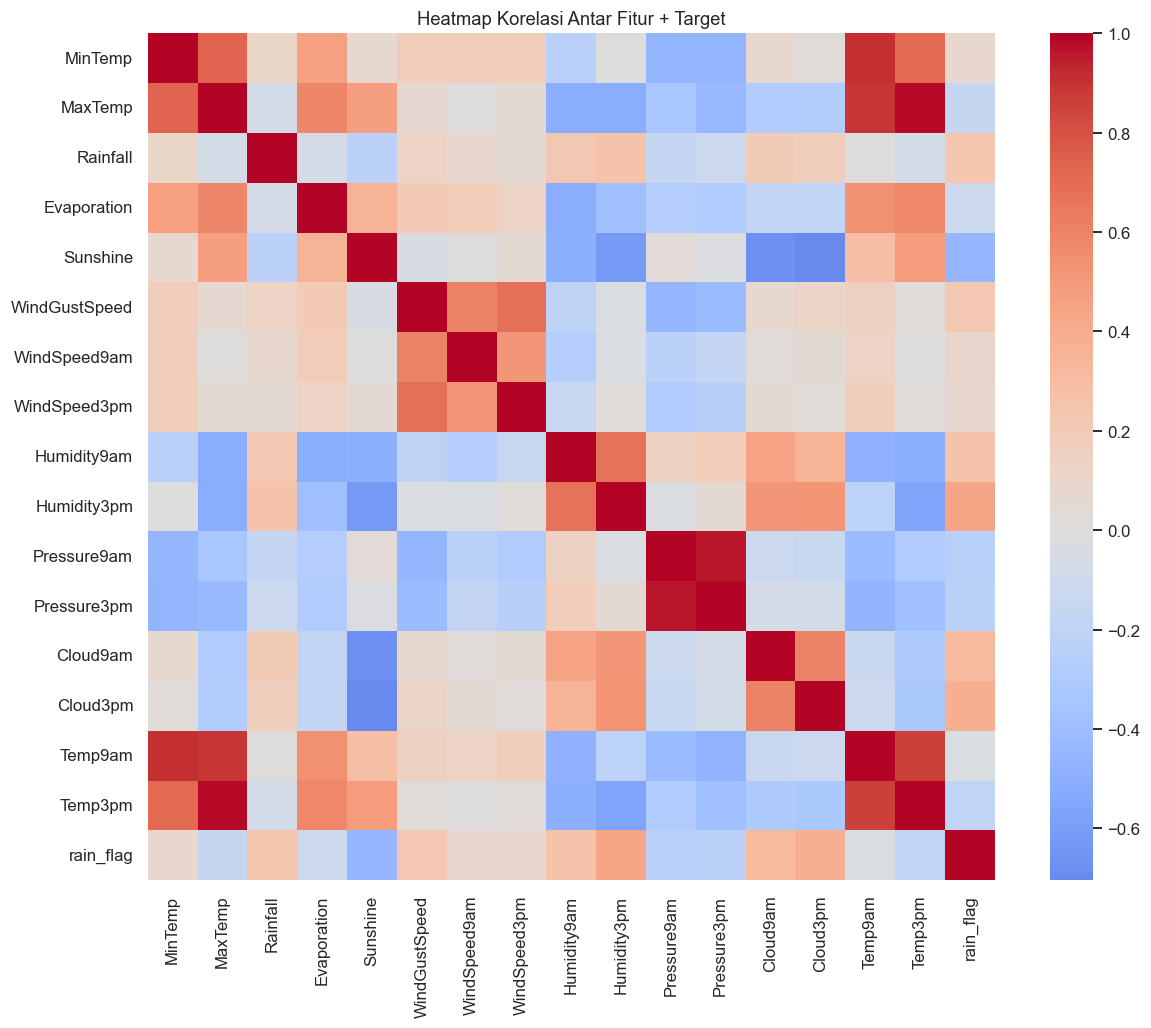

In [12]:
plt.figure(figsize=(13, 10))
sns.heatmap(dta[num_cols + ["rain_flag"]].corr(), cmap="coolwarm", center=0, square=True)
plt.title("Heatmap Korelasi Antar Fitur + Target")
plt.show()

In [13]:
print(dta[["Rainfall", "WindGustSpeed", "MaxTemp", "Pressure9am"]].describe().round(1))
print("\nRainfall > 200mm (ekstrem):", (dta['Rainfall'] > 200).sum(), "baris")
print("Rainfall < 0 (invalid)   :", (dta['Rainfall'] < 0).sum())

       Rainfall  WindGustSpeed   MaxTemp  Pressure9am
count  140787.0       132923.0  141871.0     128179.0
mean        2.3           40.0      23.2       1017.7
std         8.5           13.6       7.1          7.1
min         0.0            6.0      -4.8        980.5
25%         0.0           31.0      17.9       1012.9
50%         0.0           39.0      22.6       1017.6
75%         0.8           48.0      28.2       1022.4
max       371.0          135.0      48.1       1041.0

Rainfall > 200mm (ekstrem): 14 baris
Rainfall < 0 (invalid)   : 0


### 2.8 Ringkasan Insight EDA
1. **Data besar & time-series** (145k baris, ~10 tahun, 49 lokasi) → **wajib time-based split**, bukan random.
2. **Target imbalance** No 77,6% vs Yes 22,4% (1:3,5) → nilai pakai **F1/Recall/ROC-AUC**, bukan Accuracy saja.
3. **Missing parah** di Sunshine (48%), Evaporation (43%), Cloud3pm (41%), Cloud9am (38%) → **keputusan tim**: drop vs imputasi.
4. **Location sangat berpengaruh** (gap ~30 poin: Woomera 6,8% vs Portland 36,5%).
5. **Prediktor terkuat**: `Humidity3pm` (+0,45), `Sunshine` (−0,45), `Cloud3pm` (+0,38) — perhatikan Sunshine/Cloud missing-nya besar.
6. **Musiman**: terbasah Juli (27%, musim dingin), terkering Januari (19%).
7. **`RainToday` sinyal kuat & aman**: jika hari ini hujan → 46% besok hujan; jika tidak → 15%.
8. **Outlier** ada (Rainfall maks 371mm) tapi tidak ada nilai invalid → tree model umumnya tahan.

## 3. Data Pre-processing

In [14]:
data = df.dropna(subset=["RainTomorrow"]).copy()
data["y"] = data["RainTomorrow"].map({"Yes": 1, "No": 0})

# Feature engineering tanggal (musiman). 'Year' TIDAK dijadikan fitur (hindari ekstrapolasi).
data["Month"] = data["Date"].dt.month
data["Season"] = data["Month"].map(lambda m: (m % 12) // 3)   # 0=Des-Feb ... 2=Jun-Agu
data = data.sort_values("Date").reset_index(drop=True)         # urut waktu utk split
data = data.drop(columns=["Date", "RainTomorrow"])

# 🔧 KEPUTUSAN TIM -> strategi missing value. Ganti "impute" jadi "drop" untuk eksperimen.
MISSING_STRATEGY = "impute"
HIGH_MISS = ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm"]
if MISSING_STRATEGY == "drop":
    data = data.drop(columns=[c for c in HIGH_MISS if c in data.columns])
    print("Strategi 'drop': membuang", HIGH_MISS)
else:
    print("Strategi 'impute': semua kolom dipertahankan, missing diisi lewat SimpleImputer")

cat_cols = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]
num_cols = [c for c in data.columns if c not in cat_cols + ["y"] and data[c].dtype != "object"]
print(f"Fitur -> numeric: {len(num_cols)}, categorical: {len(cat_cols)}")

Strategi 'impute': semua kolom dipertahankan, missing diisi lewat SimpleImputer
Fitur -> numeric: 18, categorical: 5


In [15]:
# TIME-BASED SPLIT: 80% data lama (train), 20% data terbaru (test) -> hindari data leakage
split = int(len(data) * 0.8)
X = data.drop(columns="y"); y = data["y"]
X_tr, X_te, y_tr, y_te = X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"Train: {len(X_tr):,}   Test: {len(X_te):,}   scale_pos_weight = {pos_weight:.2f}")

Train: 113,754   Test: 28,439   scale_pos_weight = 3.46


In [16]:
pre = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
])
print("Preprocessor siap (imputasi + scaling numerik, imputasi + one-hot kategorik).")

Preprocessor siap (imputasi + scaling numerik, imputasi + one-hot kategorik).


## 4. Model Training & Perbandingan

In [17]:
models = {
    "LogisticRegression": Pipeline([("pre", pre), ("clf",
        LogisticRegression(max_iter=2000, class_weight="balanced", n_jobs=-1, random_state=42))]),
    "RandomForest": Pipeline([("pre", pre), ("clf",
        RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42))]),
    "XGBoost": Pipeline([("pre", pre), ("clf",
        XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.9,
                      colsample_bytree=0.9, scale_pos_weight=pos_weight,
                      eval_metric="logloss", tree_method="hist", n_jobs=-1, random_state=42))]),
}

rows = []; fitted = {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict(X_te); pr = m.predict_proba(X_te)[:, 1]
    rows.append(dict(Model=name,
                     Accuracy=accuracy_score(y_te, p), Precision=precision_score(y_te, p),
                     Recall=recall_score(y_te, p), F1=f1_score(y_te, p),
                     ROC_AUC=roc_auc_score(y_te, pr)))
    fitted[name] = m
    print(f"{name:20s} F1={rows[-1]['F1']:.4f}  ROC-AUC={rows[-1]['ROC_AUC']:.4f}")

res = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
res.round(4)

LogisticRegression   F1=0.6144  ROC-AUC=0.8584


RandomForest         F1=0.6434  ROC-AUC=0.8750


XGBoost              F1=0.6541  ROC-AUC=0.8851


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,0.8174,0.5666,0.7735,0.6541,0.8851
1,RandomForest,0.8423,0.6495,0.6374,0.6434,0.8750
2,LogisticRegression,0.7954,0.5302,0.7303,0.6144,0.8584


## 5. Evaluasi Model Terbaik

Model terbaik: XGBoost 

              precision    recall  f1-score   support

          No       0.93      0.83      0.88     22091
         Yes       0.57      0.77      0.65      6348

    accuracy                           0.82     28439
   macro avg       0.75      0.80      0.76     28439
weighted avg       0.85      0.82      0.83     28439



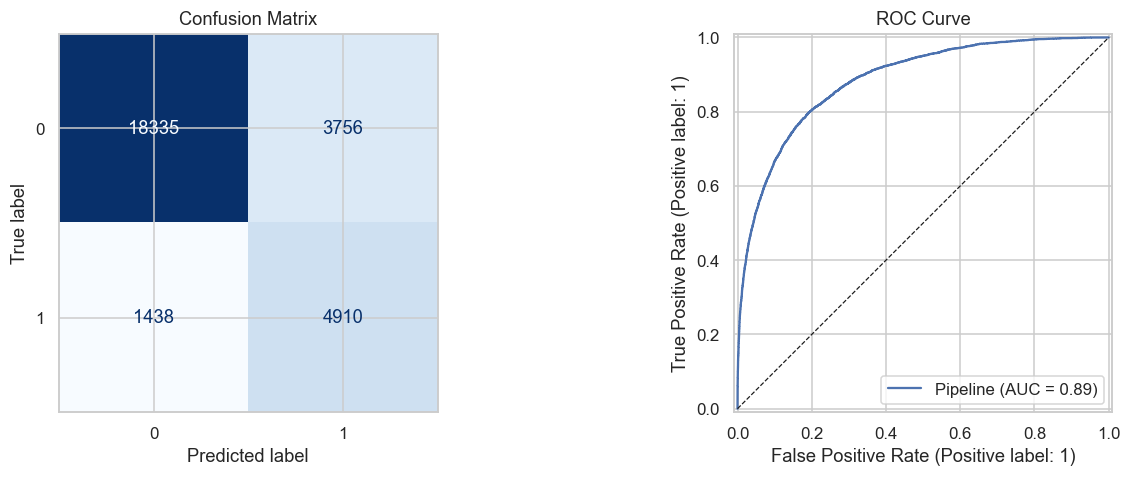

In [18]:
best_name = res.iloc[0]["Model"]; best = fitted[best_name]
print("Model terbaik:", best_name, "\n")
print(classification_report(y_te, best.predict(X_te), target_names=["No", "Yes"]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay.from_estimator(best, X_te, y_te, ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix")
RocCurveDisplay.from_estimator(best, X_te, y_te, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].set_title("ROC Curve")
plt.tight_layout(); plt.show()

> **Eksperimen A/B missing-handling:** jalankan ulang bagian pre-processing dengan
> `MISSING_STRATEGY = "drop"`, lalu bandingkan tabel hasil. Pada data ini **drop ≈ impute**
> (F1 XGBoost 0.653 vs 0.652) → kolom ber-missing tinggi (Sunshine, Evaporation, Cloud)
> **redundan**; sinyal hujan sudah diwakili `Humidity3pm` & `Pressure`.

## 6. Simpan Model (untuk Deployment Streamlit)

In [19]:
meta = {
    "model_name": best_name,
    "num_cols": num_cols, "cat_cols": cat_cols,
    "num_defaults": {c: float(data[c].median()) for c in num_cols},
    "cat_options": {c: sorted(data[c].dropna().unique().tolist()) for c in cat_cols},
    "cat_defaults": {c: data[c].mode(dropna=True).iloc[0] for c in cat_cols},
    "feature_order": num_cols + cat_cols,
    "missing_strategy": MISSING_STRATEGY,
}
joblib.dump(best, "rain_model.pkl")
joblib.dump(meta, "feature_meta.pkl")

try:  # auto-download kalau di Colab
    from google.colab import files
    files.download("rain_model.pkl"); files.download("feature_meta.pkl")
except Exception:
    pass
print("Tersimpan: rain_model.pkl + feature_meta.pkl")

Tersimpan: rain_model.pkl + feature_meta.pkl


## 7. Deployment
Source code Streamlit ada di `src/app.py`. Cara menjalankan:
```bash
streamlit run src/app.py
```
App membaca `artifacts/rain_model.pkl` + `feature_meta.pkl`, menampilkan form input cuaca,
lalu mengeluarkan **prediksi + probabilitas hujan besok** untuk data baru.

**Deliverables (1 zip):** dataset CSV · link Colab notebook ini · slides `.pptx` · source code Streamlit.